# Clinical report: is the system usable, and is each phase better than the last?

Reads the **clinical reports** under `outputs/experiments/` (written by `scripts/model/evaluate_mil.py` for every
evaluation, and by `scripts/model/clinical_report.py` for seed ensembles). Nothing is trained or written.

AUROC says how well the model *ranks* scans. A reader of the output cares about something else:
**how many false labels and missed findings a scan gets**, whether **the same scan gets the same answer** when it is
reconstructed with another kernel, and whether a probability of 0.7 **means** 70 %. This notebook answers that, for
every config and phase side by side, so the same yardstick applies to the frozen MIL models, LoRA, slice
selection and (later) NHRD.

**How the output is read.** Per label, two thresholds are chosen on **val** and applied unchanged to test
(`configs/model/clinical.yaml`):

| output | rule | meaning |
|---|---|---|
| **present** | p ≥ *report* threshold (val specificity ≥ 0.95) | reported to the reader |
| **uncertain** | in between | a human looks |
| **absent** | p < *rule-out* threshold (val sensitivity ≥ 0.90) | ruled out |

The phase-1 *max-F1* threshold is kept as `maxf1_*` for comparison only.

1. **Scorecard** -- the headline numbers of every config.
2. **Label status** -- which findings pass the gate (supported / review / not supported) and why.
3. **Report rule vs max-F1** -- the false-label / missed-finding trade-off.
4. **Kernel robustness** -- the same scan, sharp vs soft reconstruction.
5. **Calibration** -- reliability, sharp vs soft.
6. **Decision curves** -- net benefit of the top findings.
7. **Per scan** -- the distribution of false labels per scan.
8. **Phase gate** -- the chosen config against the baseline and the targets for moving on to slice selection.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# run from the repository root, wherever the notebook was opened
root = Path.cwd().resolve()
while not (root / "configs" / "preprocessing.yaml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)

from ct_model.clinical import load_clinical_config
from ct_model.training.results import load_results

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)

## Settings

- `OUTPUT_DIR`: the experiments folder.
- `EVAL_SPLIT`: which evaluations to compare (normally `test`).
- `BASELINE`: the config every other one is compared with (first 8 characters of its hash): the phase-1 reference.
- `NICKNAMES`: optional readable names per config hash.

In [2]:
OUTPUT_DIR = "outputs/experiments"
EVAL_SPLIT = "test"
BASELINE = "da82a90e"          # per-label ABMIL, BCE, 30 epochs: the best phase-1 config
NICKNAMES = {
    "da82a90e": "phase 1: per-label ABMIL",
    "3e8a8f11": "phase 1: mean pool",
    "d5a85e2a": "phase 1: single ABMIL",
}

cfg = load_clinical_config()
res = load_results(OUTPUT_DIR)
clin = res.clinical
if clin.empty:
    raise SystemExit("no clinical reports yet -- python scripts/model/clinical_report.py --experiment-dir <config folder> --per-seed")
clin = clin[(clin.eval_split == EVAL_SPLIT)].sort_values("reported").drop_duplicates(["run_id", "eval"], keep="last")
clin["config"] = clin.hash8.map(NICKNAMES).fillna(clin.name + " [" + clin.hash8 + "]")
labels = res.clinical_labels
labels = labels[labels.dir.isin(clin.dir)] if "dir" in labels else labels.merge(clin[["run_id", "eval"]], on=["run_id", "eval"])
labels = labels.merge(clin[["run_id", "eval", "config"]], on=["run_id", "eval"], how="left")
ens = clin[clin.ensemble]
print(f"{len(clin)} reports ({len(ens)} seed ensembles) on {EVAL_SPLIT}; clinical settings {cfg.fingerprint()}: "
      f"report specificity {cfg.operating_points.report_specificity}, rule-out sensitivity {cfg.operating_points.ruleout_sensitivity}")

18 reports (3 seed ensembles) on test; clinical settings 064765f05f87: report specificity 0.95, rule-out sensitivity 0.9


## 1. Scorecard

One row per config: the **seed ensemble** (probabilities averaged over its seeds), and the mean ± std of its single
seeds. Read it left to right:

- `supported`: findings that pass every gate rule (section 2). The number that has to go up.
- `FP/scan`, `missed/scan`: false labels and missed findings per scan at the **report** threshold; `normal flagged`:
  the share of scans with no finding that still get a label.
- `sens` / `spec`: macro over the 18 findings at the report threshold. `uncertain/scan`: labels left to a human.
- `paired flip`: share of scans whose sharp and soft reconstructions get a **different** report decision for at least
  one finding. `sens sharp` / `sens soft`: the kernel gap at the report threshold.
- `ECE`: expected calibration error after calibration on val.

In [3]:
COLS = {
    "labels_supported": "supported", "labels_review": "review", "macro_auroc": "AUROC",
    "report_fp_per_scan": "FP/scan", "report_fn_per_scan": "missed/scan", "report_normal_flag_rate": "normal flagged",
    "report_macro_sens": "sens", "report_macro_spec": "spec", "report_macro_ppv": "PPV",
    "uncertain_per_scan": "uncertain/scan", "paired_scans_with_flip": "paired flip",
    "report_macro_sens[sharp]": "sens sharp", "report_macro_sens[soft]": "sens soft",
    "macro_ece[sharp]": "ECE sharp", "macro_ece[soft]": "ECE soft",
}
cols = [c for c in COLS if c in clin.columns]
card = ens.set_index("config")[cols].rename(columns=COLS)
card.insert(0, "seeds", ens.set_index("config").members)
display(card.sort_values(["supported", "AUROC"], ascending=False).style.format(precision=3))

single = clin[~clin.ensemble].groupby("config")[cols]
seeds = single.mean().round(3).astype(str) + " ± " + single.std().round(3).astype(str)
print("single seeds, mean ± std:")
display(seeds.rename(columns=COLS))

,seeds,supported,review,AUROC,FP/scan,missed/scan,normal flagged,sens,spec,PPV,uncertain/scan,paired flip,sens sharp,sens soft,ECE sharp,ECE soft
config,,,,,,,,,,,,,,,,
phase 1: mean pool,5,2,0,0.786,0.719,2.503,0.090,0.316,0.951,0.542,7.062,0.495,0.361,0.277,0.020,0.064
phase 1: single ABMIL,5,1,1,0.796,0.695,2.479,0.055,0.318,0.952,0.550,7.211,0.462,0.373,0.270,0.019,0.057
phase 1: per-label ABMIL,5,0,1,0.797,0.643,2.505,0.069,0.313,0.956,0.565,7.014,0.482,0.370,0.265,0.020,0.059


single seeds, mean ± std:


,supported,review,AUROC,FP/scan,missed/scan,normal flagged,sens,spec,PPV,uncertain/scan,paired flip,sens sharp,sens soft,ECE sharp,ECE soft
config,,,,,,,,,,,,,,,
phase 1: mean pool,1.6 ± 0.548,0.4 ± 0.548,0.782 ± 0.003,0.73 ± 0.041,2.512 ± 0.041,0.089 ± 0.012,0.311 ± 0.012,0.95 ± 0.003,0.536 ± 0.005,7.066 ± 0.201,0.504 ± 0.017,0.357 ± 0.004,0.271 ± 0.026,0.021 ± 0.001,0.067 ± 0.003
phase 1: per-label ABMIL,0.8 ± 0.837,0.6 ± 0.548,0.793 ± 0.003,0.669 ± 0.031,2.501 ± 0.039,0.07 ± 0.009,0.313 ± 0.01,0.954 ± 0.002,0.555 ± 0.003,7.036 ± 0.155,0.508 ± 0.011,0.367 ± 0.002,0.268 ± 0.019,0.02 ± 0.001,0.061 ± 0.006
phase 1: single ABMIL,0.8 ± 0.837,0.8 ± 0.447,0.79 ± 0.002,0.723 ± 0.052,2.48 ± 0.043,0.07 ± 0.015,0.317 ± 0.013,0.95 ± 0.004,0.542 ± 0.007,7.303 ± 0.119,0.481 ± 0.017,0.365 ± 0.004,0.277 ± 0.027,0.02 ± 0.001,0.059 ± 0.006


## 2. Label status

Per finding, the status of every config's ensemble. A finding is **not supported** when it fails a *discrimination* rule
(the lower end of the AUROC CI, or the sensitivity at the report threshold), **review** when only calibration or
robustness fails, **supported** when it passes all. The second table shows why, for the baseline.

In [4]:
ens_labels = labels[(labels.group_by == "all") & labels.run_id.isin(ens.run_id)]
status = ens_labels.pivot_table(index="finding", columns="config", values="status", aggfunc="first")
order = ens_labels[ens_labels.config == ens.config[ens.hash8 == BASELINE].iloc[0]].set_index("finding").auroc.sort_values(ascending=False).index \
    if (ens.hash8 == BASELINE).any() else status.index
COLORS = {"supported": "background-color: #c8e6c9", "review": "background-color: #fff3c4", "not_supported": "background-color: #f8d0d0"}
display(status.loc[[f for f in order if f in status.index]].style.map(lambda v: COLORS.get(v, "")))

base_dir = ens.dir[ens.hash8 == BASELINE]
if len(base_dir):
    gate = pd.read_csv(Path(base_dir.iloc[0]) / "gate.csv").set_index("label")
    print(f"why, for the baseline ({BASELINE}) -- rules: AUROC CI low >= {cfg.gate.auroc_ci_low}, report sensitivity >= "
          f"{cfg.gate.report_sensitivity}, ECE <= {cfg.gate.ece}, paired flip <= {cfg.gate.paired_flip_rate}, "
          f"|soft - sharp| sensitivity <= {cfg.gate.kernel_sensitivity_gap}")
    display(gate[["auroc_ci_low", "report_sens", "ece", "paired_flip_rate", "kernel_sens_gap", "status"]]
            .sort_values("auroc_ci_low", ascending=False).style.format(precision=3, na_rep="n/a"))

config,phase 1: mean pool,phase 1: per-label ABMIL,phase 1: single ABMIL
finding,,,
pleural_effusion,supported,review,review
cardiomegaly,supported,not_supported,supported
arterial_wall_calcification,not_supported,not_supported,not_supported
coronary_artery_wall_calcification,not_supported,not_supported,not_supported
interlobular_septal_thickening,not_supported,not_supported,not_supported
pericardial_effusion,not_supported,not_supported,not_supported
mosaic_attenuation_pattern,not_supported,not_supported,not_supported
medical_material,not_supported,not_supported,not_supported
consolidation,not_supported,not_supported,not_supported


why, for the baseline (da82a90e) -- rules: AUROC CI low >= 0.8, report sensitivity >= 0.6, ECE <= 0.05, paired flip <= 0.1, |soft - sharp| sensitivity <= 0.1


,auroc_ci_low,report_sens,ece,paired_flip_rate,kernel_sens_gap,status
label,,,,,,
pleural_effusion,0.932,0.777,0.024,0.048,-0.102,review
cardiomegaly,0.909,0.572,0.017,0.039,-0.054,not_supported
arterial_wall_calcification,0.860,0.453,0.044,0.077,-0.094,not_supported
coronary_artery_wall_calcification,0.848,0.344,0.043,0.085,-0.168,not_supported
interlobular_septal_thickening,0.828,0.341,0.016,0.044,-0.149,not_supported
pericardial_effusion,0.803,0.442,0.013,0.033,-0.051,not_supported
mosaic_attenuation_pattern,0.801,0.375,0.016,0.060,-0.166,not_supported
medical_material,0.791,0.412,0.024,0.080,0.090,not_supported
consolidation,0.791,0.267,0.033,0.059,0.009,not_supported


## 3. Report rule vs max-F1: the false-label / missed-finding trade-off

The same models under the two rules. Max-F1 (phase 1) catches more findings but floods the reader with false labels;
the report rule (val specificity 0.95) keeps false labels low and hands the uncertain middle to a human. Neither rule
changes the ranking -- only a better model moves both bars down at once.

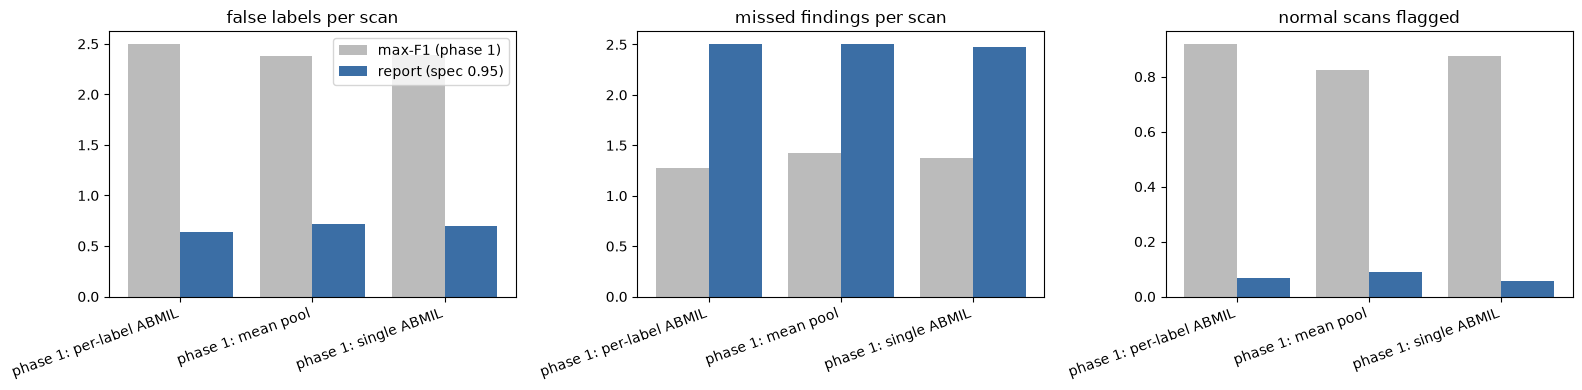

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = np.arange(len(ens))
for ax, (metric, title) in zip(axes, [("fp_per_scan", "false labels per scan"), ("fn_per_scan", "missed findings per scan"),
                                      ("normal_flag_rate", "normal scans flagged")]):
    ax.bar(x - 0.2, ens[f"maxf1_{metric}"], 0.4, label="max-F1 (phase 1)", color="#bbbbbb")
    ax.bar(x + 0.2, ens[f"report_{metric}"], 0.4, label="report (spec 0.95)", color="#3b6ea5")
    ax.set_xticks(x, ens.config, rotation=20, ha="right"); ax.set_title(title)
axes[0].legend()
plt.tight_layout(); plt.show()

## 4. Kernel robustness: the same scan, sharp vs soft

Test holds both reconstructions of each scan. Left: per finding, the share of paired scans whose report decision
differs between the two kernels. Right: per finding, the sensitivity at the report threshold on sharp vs soft scans
(below the diagonal = the unseen soft kernel misses more). Training and the val thresholds saw only sharp scans
until the soft subset (train-soft-1000) was added.

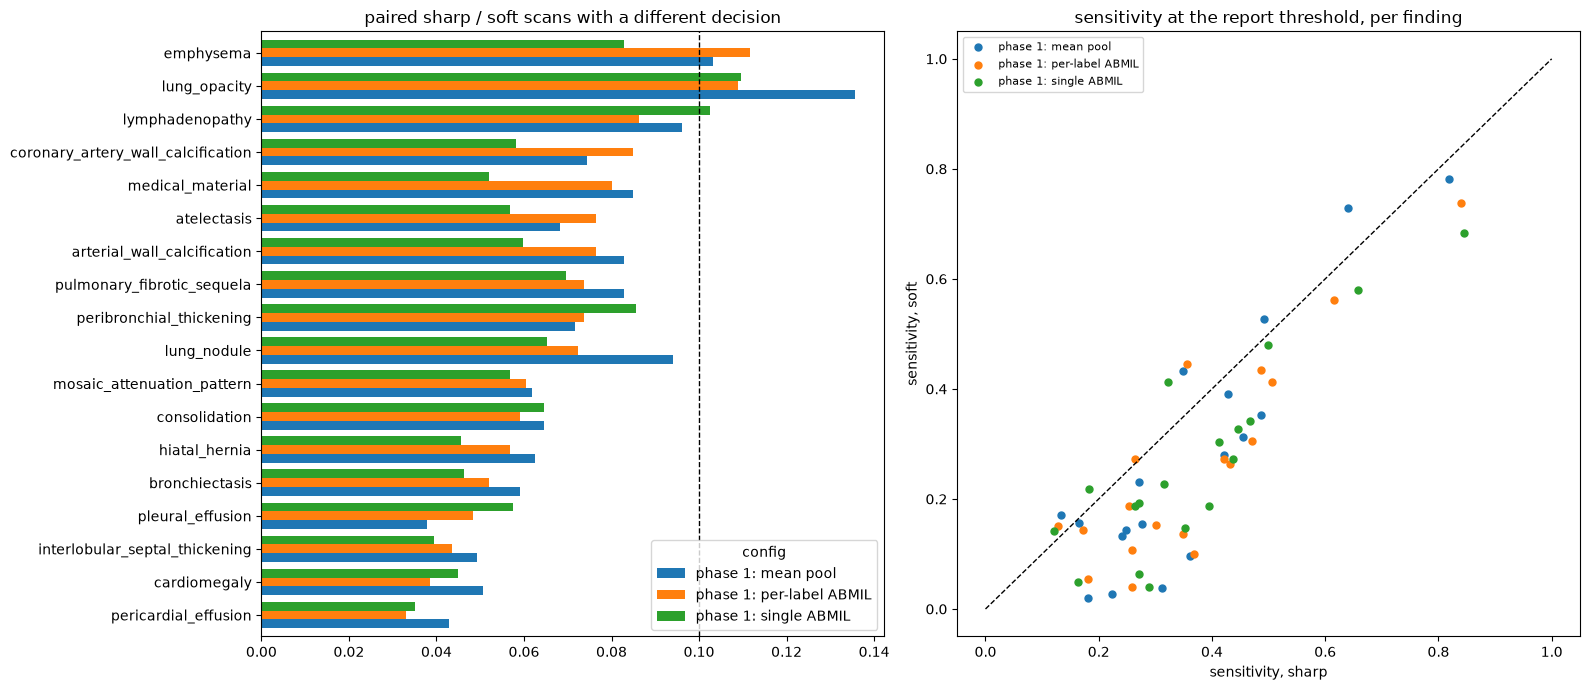

In [6]:
paired = []
for _, r in ens.iterrows():
    f = Path(r.dir) / "paired_kernel.csv"
    if f.is_file():
        paired.append(pd.read_csv(f).assign(config=r.config))
if paired:
    paired = pd.concat(paired)
    flip = paired.pivot_table(index="label", columns="config", values="flip_rate").sort_values(paired.config.iloc[0])
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    flip.plot.barh(ax=axes[0], width=0.8); axes[0].axvline(cfg.gate.paired_flip_rate, color="k", ls="--", lw=1)
    axes[0].set_title("paired sharp / soft scans with a different decision"); axes[0].set_ylabel("")
    k = labels[(labels.group_by == "kernel_class") & labels.run_id.isin(ens.run_id)]
    ks = k.pivot_table(index=["config", "finding"], columns="group", values="report_sens").reset_index()
    for name, part in ks.groupby("config"):
        axes[1].scatter(part.sharp, part.soft, label=name, s=25)
    axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_xlabel("sensitivity, sharp"); axes[1].set_ylabel("sensitivity, soft")
    axes[1].set_title("sensitivity at the report threshold, per finding"); axes[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("no paired reconstructions in these evaluations")

## 5. Calibration: does p = 0.7 mean 70 %?

Reliability of the calibrated probabilities of one report (`REPORT`, default the baseline ensemble), every finding
pooled, sharp vs soft. Calibration is fitted on val; a val split without soft scans cannot calibrate them.

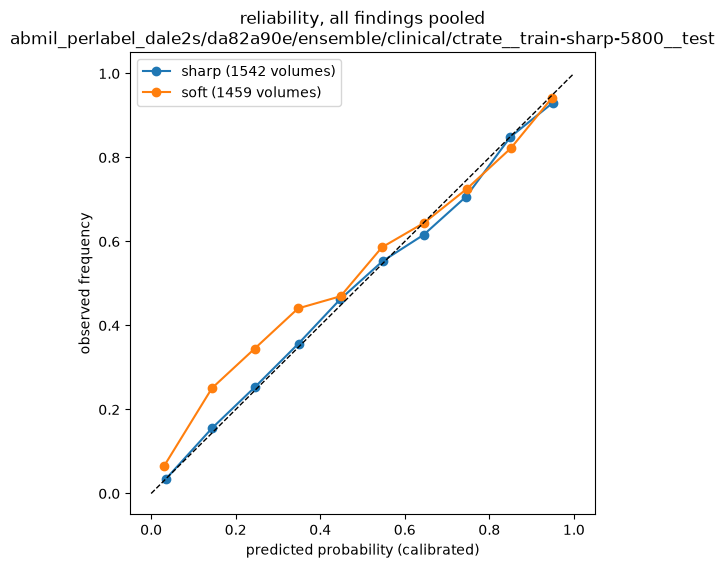

In [7]:
REPORT = None   # a report folder; None = the baseline ensemble
folder = Path(REPORT) if REPORT else Path(base_dir.iloc[0] if len(base_dir) else ens.dir.iloc[0])
pc = pd.read_csv(folder / "predictions_clinical.csv")
finds = [c[4:] for c in pc.columns if c.startswith("cal_")]
fig, ax = plt.subplots(figsize=(6, 6))
for kc, part in pc.groupby("kernel_class"):
    if kc not in ("sharp", "soft"):
        continue
    p = part[[f"cal_{f}" for f in finds]].to_numpy().ravel(); y = part[[f"true_{f}" for f in finds]].to_numpy().ravel()
    keep = ~np.isnan(y); p, y = p[keep], y[keep]
    bins = np.clip((p * 10).astype(int), 0, 9)
    xs = [p[bins == b].mean() for b in range(10) if (bins == b).sum() > 20]
    ys = [y[bins == b].mean() for b in range(10) if (bins == b).sum() > 20]
    ax.plot(xs, ys, "o-", label=f"{kc} ({len(part)} volumes)")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted probability (calibrated)"); ax.set_ylabel("observed frequency")
ax.set_title(f"reliability, all findings pooled\n{folder.relative_to(OUTPUT_DIR) if folder.is_relative_to(OUTPUT_DIR) else folder}")
ax.legend(); plt.show()

## 6. Decision curves

Net benefit of acting on the model (threshold probability *pt* on the calibrated output) vs acting on every scan or
none, for the findings with the highest AUROC in `REPORT`. A curve above both references means the model adds value
at that trade-off between a false label and a missed finding.

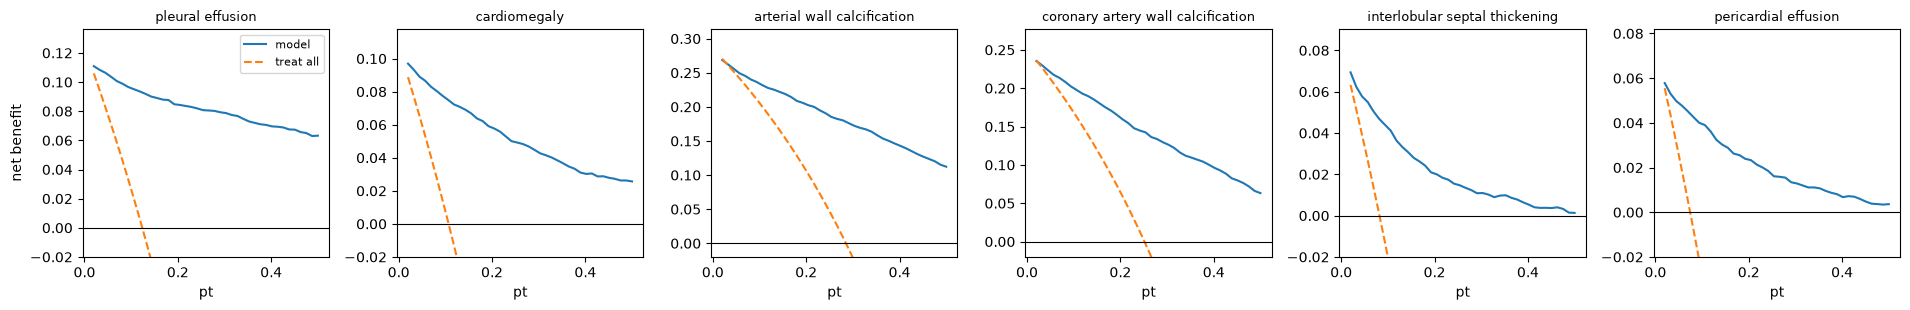

In [8]:
TOP = 6
y_all = pc[[f"true_{f}" for f in finds]].to_numpy(); p_all = pc[[f"cal_{f}" for f in finds]].to_numpy()
la = pd.read_csv(folder / "per_label.csv"); la = la[la.group_by == "all"].set_index("label").auroc.sort_values(ascending=False)
pts = np.linspace(0.02, 0.5, 40)
fig, axes = plt.subplots(1, TOP, figsize=(3.2 * TOP, 3.2), sharey=False)
for ax, f in zip(axes, la.index[:TOP]):
    c = finds.index(f); keep = ~np.isnan(y_all[:, c]); y, p = y_all[keep, c], p_all[keep, c]
    w = pts / (1 - pts)
    model = [((p >= t) & (y == 1)).mean() - wt * ((p >= t) & (y == 0)).mean() for t, wt in zip(pts, w)]
    every = y.mean() - w * (1 - y.mean())
    ax.plot(pts, model, label="model"); ax.plot(pts, every, label="treat all", ls="--"); ax.axhline(0, color="k", lw=0.8)
    ax.set_ylim(-0.02, max(0.05, y.mean() * 1.1)); ax.set_title(f.replace("_", " "), fontsize=9); ax.set_xlabel("pt")
axes[0].set_ylabel("net benefit"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Per scan: how many false labels does a reader see?

Distribution of false labels per scan at the report threshold (left) and the phase-1 max-F1 threshold (right), for
`REPORT`. The mean hides the tail: a few scans with many false labels cost a reader's trust more than many with one.

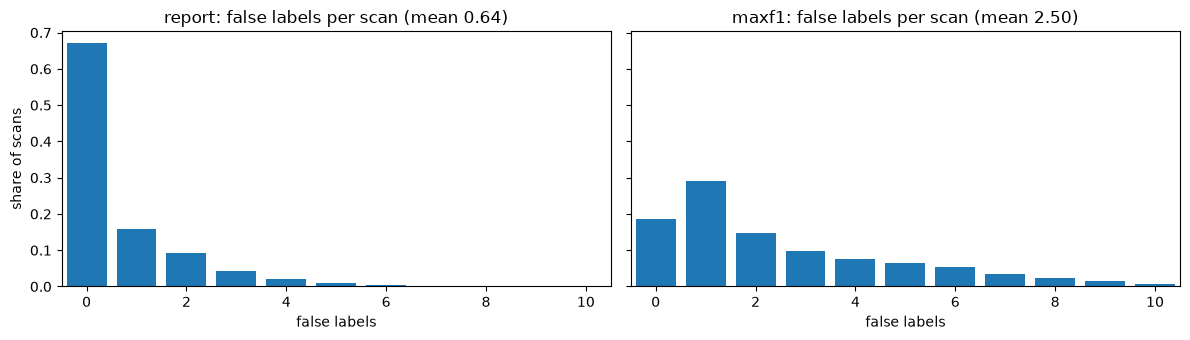

              report_fp  report_fn  n_uncertain  maxf1_fp  maxf1_fn
kernel_class                                                       
other              1.00       3.33         4.08      2.50      2.83
sharp              0.78       2.28         7.85      2.96      0.96
soft               0.48       2.72         6.20      2.01      1.57


In [9]:
scans = pd.read_csv(folder / "per_scan.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, rule in zip(axes, ["report", "maxf1"]):
    counts = scans[f"{rule}_fp"].value_counts().sort_index()
    ax.bar(counts.index, counts.values / len(scans)); ax.set_title(f"{rule}: false labels per scan (mean {scans[f'{rule}_fp'].mean():.2f})")
    ax.set_xlabel("false labels"); ax.set_xlim(-0.5, 10.5)
axes[0].set_ylabel("share of scans")
plt.tight_layout(); plt.show()
print(scans.groupby("kernel_class")[["report_fp", "report_fn", "n_uncertain", "maxf1_fp", "maxf1_fn"]].mean().round(2))

## 8. Phase gate: ready for content-aware slice selection?

The targets of the plan (docs/model/architecture.md, "Roadmap"), checked for every config against the baseline. Slice
selection starts only when one config passes all of them: then the encoder is final, and selectors are scored against
its full-depth clinical report.

In [10]:
if (ens.hash8 == BASELINE).any():
    b = ens[ens.hash8 == BASELINE].iloc[0]
    rows = []
    for _, r in ens.iterrows():
        gap = r.get("report_macro_sens[soft]", np.nan) - r.get("report_macro_sens[sharp]", np.nan)
        rows.append({
            "config": r.config,
            "paired flip <= half of baseline": r.paired_scans_with_flip <= b.paired_scans_with_flip / 2,
            "|soft - sharp| sens <= 0.05": abs(gap) <= 0.05,
            "FP/scan not worse": r.report_fp_per_scan <= b.report_fp_per_scan + 1e-9,
            "more labels supported": r.labels_supported > b.labels_supported,
            "paired flip": round(r.paired_scans_with_flip, 3), "soft - sharp sens": round(gap, 3),
            "FP/scan": round(r.report_fp_per_scan, 3), "supported": int(r.labels_supported),
        })
    display(pd.DataFrame(rows).set_index("config"))
else:
    print(f"baseline {BASELINE} has no ensemble report yet")

,paired flip <= half of baseline,|soft - sharp| sens <= 0.05,FP/scan not worse,more labels supported,paired flip,soft - sharp sens,FP/scan,supported
config,,,,,,,,
phase 1: per-label ABMIL,False,False,True,False,0.482,-0.104,0.643,0
phase 1: mean pool,False,False,False,True,0.495,-0.085,0.719,2
phase 1: single ABMIL,False,False,False,True,0.462,-0.103,0.695,1
